# 22 — Representation screen: does any condition representation predict response geometry?

**Verdict (plain language).**
1. **ESM2 does not predict response geometry.** On the 46 reliable responders, Spearman ρ is 0.046 (raw, Mantel p = 0.18) and 0.044 (centred, p = 0.10); on all 90 it is −0.017 (p = 0.72) and 0.003 (p = 0.37). It is indistinguishable from the random-vector control (ρ 0.035, p = 0.13). The raw ESM2 vectors are also nearly collinear (median cosine distance 0.05), so centring is needed before the geometry means anything.
2. **Only two representations show any signal, and it is weak.** Signed binding: ρ = 0.108, Mantel p = 0.0009 (reliable); ρ = 0.034, p = 0.027 (all 90). Family one-hot: ρ = 0.134, p = 0.0003 (reliable); ρ = 0.067, p = 0.001 (all 90). Even the best ρ explains about 2 % of the rank variance of D_response. Uncorrected p-values, 7 representations x 2 subsets.
3. **Does binding beat ESM2? Directionally yes, but not demonstrably.** Binding minus ESM2-raw ρ = +0.060 (reliable), 95 % object-bootstrap CI [−0.09, 0.21]; +0.050 (all 90), CI [−0.03, 0.13]. Binding does not beat the family one-hot (−0.027 and −0.032), so the binding signal may be largely the family signal; this screen cannot separate them.
4. **Per cell type:** binding and family correlate in every cell type for the reliable set (binding Mantel p < 0.035 in all 14). Family ρ is highest in myeloid cells (CD14 Mono 0.143, cDC 0.149) and lower in T cells (CD4 Memory 0.080, CD4 Naive 0.095), but it is not absent there (p ≤ 0.015). No cell-type correction applied.
5. **Reading for Stage B:** no representation predicts response geometry strongly. If Stage B depends on ESM2 carrying response information, this screen does not support it. If it depends on any condition representation carrying some, binding and family do, weakly.

**Caveats.** (a) The brief expected ~40 reliable responders; this data gives 46 at r ≥ 0.5. (b) The reported dCor is the biased V-statistic of distance matrices and is not interpretable in size: the constant control gets dCor 0.66 (p = 1.0) and random vectors 0.59. Use only the dCor permutation p. (c) 5 cytokines have no annotated receptor, so their binding distance to everything is 1.0. (d) IFN-omega has no UniProt Function text and was embedded from its gene symbol. (e) NicheNet is not used anywhere.


CPU only, no training. Decides whether Stage B happens.

**Design.** Candidate representations → 90×90 cosine-distance matrices, each compared with D_response (notebook 20; cosine distance of response vectors, 14 cell types × 2,000 genes).
* `esm2_raw`: `uns['esm2_embeddings']` (2560-d, not L2-normalised) ; `esm2_centred`: same minus the mean over the 90 cytokines ; `binding`: signed D_binding (notebook 21); `family_onehot`: `cytokine_family` one-hot; `uniprot_text`: sentence embedding (all-MiniLM-L6-v2, mean over ≤200-word chunks) of the UniProt *Function* field (human, reviewed); `constant`: all off-diagonal distances 1 (control; rank correlation undefined → reported as NaN with p = 1); `random_gauss`: 64-d Gaussian vectors (seed 0; extra calibration control).
* **NicheNet: not used** (neither here nor as a candidate), so it is not a role in this screen; notebook 21 annotations are OmniPath only.
* Statistics: (i) Spearman ρ between the flattened upper triangles. (ii) **Mantel permutation test**: object labels of the candidate matrix are permuted jointly on rows and columns (10,000 draws, seed 0, one-sided "greater", p = (1+#≥obs)/(1+10,000)); the flattened vector is never shuffled and no parametric p-value is used. (iii) **Distance correlation** computed from the two distance matrices (double-centred, V-statistic — checked below against `dcor.distance_correlation` on Euclidean data) with its own label-permutation test (same 10,000 permutations).
* Subsets: (a) the **reliable responders** (split-half r ≥ 0.5 → 46 cytokines in this data; the brief expected ~40) and (b) all 90. Also per cell type (response vector restricted to that cell type's 2,000 genes).
* Note: the 5 cytokines without an annotated receptor have an all-zero binding row; their binding distance to everything is fixed at 1.0.

In [1]:
import numpy as np, pandas as pd, anndata as ad, dcor, json, os, time, warnings, matplotlib.pyplot as plt, scipy.sparse as sp
from scipy.stats import rankdata, spearmanr
warnings.simplefilter("ignore"); pd.set_option("display.width",220,"display.max_rows",300)
A=ad.read_h5ad("../data/response_matrix.h5ad"); LIG=list(A.obs_names); n_all=len(LIG)
rel=A.obs["reliable"].values.astype(bool); ct_of=A.var["cell_type"].values; CTS=list(A.uns["cell_types_kept"])
def cosd(M):
    M=np.asarray(M,float); nn=np.linalg.norm(M,axis=1,keepdims=True); Mn=M/np.where(nn==0,1,nn); D=np.clip(1-Mn@Mn.T,0,2); np.fill_diagonal(D,0); return D
R=A.X if not sp.issparse(A.X) else A.X.toarray()
D_resp_all=cosd(R); assert np.allclose(D_resp_all,A.obsp["D_response_all"],atol=1e-5)
D_resp_ct={ct:cosd(R[:,ct_of==ct]) for ct in CTS}
print("objects:",n_all,"reliable:",rel.sum(),"cell types:",len(CTS))

objects: 90 reliable: 46 cell types: 14


## Candidate representations

In [2]:
import glob
f=glob.glob("/users/scratch1/pavelabramau/data_pavel/cellflow/hf_cache/hub/datasets--theislab--cellflow-datasets/snapshots/*/pbmc_parse.h5ad")[0]
esm=dict(ad.read_h5ad(f,backed="r").uns["esm2_embeddings"]); E=np.vstack([np.asarray(esm[c],float) for c in LIG])
print("ESM2",E.shape,"norms",E.min() if False else np.linalg.norm(E,axis=1).round(1).min(),np.linalg.norm(E,axis=1).round(1).max())
fam=A.obs["family"].astype(str).values; F=pd.get_dummies(fam).values.astype(float)
reps={}
reps["esm2_raw"]=cosd(E); reps["esm2_centred"]=cosd(E-E.mean(0))
reps["binding"]=np.load("../data/D_binding_signed.npy"); reps["family_onehot"]=cosd(F)
const=np.ones((n_all,n_all)); np.fill_diagonal(const,0); reps["constant"]=const
reps["random_gauss"]=cosd(np.random.default_rng(0).normal(size=(n_all,64)))
# UniProt text
up=pd.read_csv("../data/uniprot_function.csv").set_index("cytokine").reindex(LIG)
up["function"]=up["function"].fillna("")
print("empty UniProt function:",list(up.index[up["function"].str.len()==0]),"-> embedded from the gene symbol")
from sentence_transformers import SentenceTransformer
st=SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2",device="cpu")
def chunks(t,g,k=200):
    w=t.split(); return [" ".join(w[i:i+k]) for i in range(0,len(w),k)] or [g]
Tm=[]
for c in LIG:
    ch=chunks(up.loc[c,"function"],up.loc[c,"genes"]); Tm.append(st.encode(ch,normalize_embeddings=True).mean(0))
Tm=np.vstack(Tm); reps["uniprot_text"]=cosd(Tm)
np.save("../data/uniprot_text_embedding.npy",Tm)
for k,v in reps.items(): assert v.shape==(90,90) and np.allclose(v,v.T,atol=1e-6); print(f"{k:14s} median off-diag {np.median(v[np.triu_indices(90,1)]):.3f}")

ESM2 (90, 2560) norms 9.5 14.8
empty UniProt function: ['IFN-omega'] -> embedded from the gene symbol


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 11694.05it/s]

esm2_raw       median off-diag 0.049
esm2_centred   median off-diag 1.029
binding        median off-diag 1.000
family_onehot  median off-diag 1.000
constant       median off-diag 1.000
random_gauss   median off-diag 1.002
uniprot_text   median off-diag 0.555


## Statistics

In [3]:
def rnd(df,k=4): return df.round({c:k for c in df.select_dtypes("number").columns})
def dc(D):
    r=D.mean(0,keepdims=True); c=D.mean(1,keepdims=True); return D-r-c+D.mean()
def spear_mantel(Dc,Dr,P,chunk=1000):
    n=len(Dc); I,J=np.triu_indices(n,1); a=Dc[I,J]; b=Dr[I,J]
    if np.ptp(a)==0 or np.ptp(b)==0: return np.nan,1.0
    rb=rankdata(b); rb=(rb-rb.mean()); ra=rankdata(a); RK=np.zeros((n,n)); RK[I,J]=ra; RK=RK+RK.T
    ssa=np.sum((ra-ra.mean())**2); sd=np.sqrt(ssa*np.sum(rb**2))
    obs=np.sum((ra-ra.mean())*rb)/sd
    ge=0
    for s in range(0,len(P),chunk):
        p=P[s:s+chunk]; V=RK[p[:,I],p[:,J]]; r=(V@rb)/sd; ge+=np.sum(r>=obs-1e-12)
    return obs,(1+ge)/(1+len(P))
def dcor_perm(Dc,Dr,P,chunk=250):
    n=len(Dc); Ac=dc(Dc); Bc=dc(Dr); s=np.sqrt(np.sum(Ac**2)*np.sum(Bc**2))
    if s<1e-12: return 0.0,1.0
    obs=np.sum(Ac*Bc)/s; ge=0
    for k in range(0,len(P),chunk):
        p=P[k:k+chunk]; V=Ac[p[:,:,None],p[:,None,:]]; r=(V*Bc).sum((1,2))/s; ge+=np.sum(r>=obs-1e-12)
    return float(np.sqrt(max(obs,0))),(1+ge)/(1+len(P))
# validate against dcor on Euclidean data
rng=np.random.default_rng(1); X1=rng.normal(size=(40,5)); X2=X1[:,:2]@rng.normal(size=(2,3))+rng.normal(size=(40,3))
from scipy.spatial.distance import cdist
d1,d2=cdist(X1,X1),cdist(X2,X2); mine=np.sqrt(max(np.sum(dc(d1)*dc(d2))/np.sqrt(np.sum(dc(d1)**2)*np.sum(dc(d2)**2)),0))
print("dCor mine %.6f vs dcor package %.6f"%(mine,dcor.distance_correlation(X1,X2))); assert abs(mine-dcor.distance_correlation(X1,X2))<1e-6
NPERM=10000; rng=np.random.default_rng(0); PERMS={}
def perms(n):
    if n not in PERMS: PERMS[n]=np.vstack([rng.permutation(n) for _ in range(NPERM)])
    return PERMS[n]
def screen(Dr,idx,tag,ct):
    out=[]; P=perms(len(idx)); Drs=Dr[np.ix_(idx,idx)]
    for name,Dcand in reps.items():
        Dcs=Dcand[np.ix_(idx,idx)]; rho,pm=spear_mantel(Dcs,Drs,P); dco,pd_=dcor_perm(Dcs,Drs,P)
        out.append(dict(representation=name,subset=tag,cell_type=ct,rho=rho,mantel_p=pm,dcor=dco,dcor_p=pd_,n=len(idx)))
    return out
SUBS={"reliable":np.where(rel)[0],"all90":np.arange(n_all)}
t0=time.time(); rows=[]
for tag,idx in SUBS.items(): rows+=screen(D_resp_all,idx,tag,"all (concatenated)")
print("main tables done in %.0fs"%(time.time()-t0))
main=pd.DataFrame(rows)
for tag in SUBS: print("\n===",tag,"(n=%d)"%len(SUBS[tag])); print(rnd(main[main.subset==tag].drop(columns=["subset","cell_type"])).to_string(index=False))

dCor mine 0.762044 vs dcor package 0.762044


main tables done in 6s

=== reliable (n=46)
representation    rho  mantel_p   dcor  dcor_p  n
      esm2_raw 0.0456    0.1754 0.4935  0.0235 46
  esm2_centred 0.0439    0.0964 0.4818  0.0354 46
       binding 0.1082    0.0009 0.6373  0.0006 46
 family_onehot 0.1338    0.0003 0.5504  0.0004 46
      constant    NaN    1.0000 0.6587  1.0000 46
  random_gauss 0.0354    0.1347 0.5882  0.2245 46
  uniprot_text 0.0642    0.0977 0.6150  0.0011 46

=== all90 (n=90)
representation     rho  mantel_p   dcor  dcor_p  n
      esm2_raw -0.0170    0.7207 0.3759  0.1258 90
  esm2_centred  0.0027    0.3684 0.3627  0.1093 90
       binding  0.0340    0.0265 0.5553  0.0006 90
 family_onehot  0.0668    0.0011 0.4232  0.0007 90
      constant     NaN    1.0000 0.5999  1.0000 90
  random_gauss  0.0243    0.0660 0.4963  0.0981 90
  uniprot_text -0.0083    0.6009 0.5085  0.0016 90


In [4]:
t0=time.time()
for ct in CTS:
    for tag,idx in SUBS.items(): rows+=screen(D_resp_ct[ct],idx,tag,ct)
res=pd.DataFrame(rows); res.to_csv("../data/representation_screen.csv",index=False); print("per-cell-type done in %.0fs"%(time.time()-t0))
for tag in SUBS:
    t=res[(res.subset==tag)&(res.cell_type!="all (concatenated)")]
    print("\n=== rho per cell type —",tag); print(t.pivot(index="cell_type",columns="representation",values="rho").round(3).to_string())
    print("--- Mantel p"); print(t.pivot(index="cell_type",columns="representation",values="mantel_p").round(4).to_string())

per-cell-type done in 86s

=== rho per cell type — reliable
representation         binding  constant  esm2_centred  esm2_raw  family_onehot  random_gauss  uniprot_text
cell_type                                                                                                  
B Intermediate/Memory    0.092       NaN         0.041     0.040          0.126         0.037         0.080
B Naive                  0.099       NaN         0.041     0.042          0.135         0.030         0.077
CD14 Mono                0.110       NaN         0.023     0.029          0.143         0.041         0.061
CD16 Mono                0.104       NaN         0.027     0.023          0.134         0.038         0.060
CD4 Memory               0.071       NaN         0.019     0.026          0.080         0.023         0.026
CD4 Naive                0.104       NaN         0.026     0.030          0.095         0.029         0.042
CD8 Memory               0.061       NaN         0.018     0.020          0.

## Does binding beat ESM2? Object-level bootstrap of the rho difference

In [5]:
# Two separate p-values do not answer "is A better than B". Resample OBJECTS (cytokines) with replacement, drop pairs of a cytokine with itself,
# recompute both Spearman rhos on the same resample, and look at the difference. 2,000 resamples, seed 0.
from scipy.stats import spearmanr
def boot_diff(a,b,Dr,idx,B=2000,seed=0):
    r=np.random.default_rng(seed); n=len(idx); I,J=np.triu_indices(n,1); out=[]
    for _ in range(B):
        s=idx[r.integers(0,n,n)]; m=s[I]!=s[J]; i,j=s[I][m],s[J][m]
        y=Dr[i,j]; out.append(spearmanr(a[i,j],y)[0]-spearmanr(b[i,j],y)[0])
    out=np.array(out); return np.nanmean(out),np.nanpercentile(out,[2.5,97.5]),np.nanmean(out<=0)
brows=[]
for tag,idx in SUBS.items():
    for other in ["esm2_raw","esm2_centred","family_onehot"]:
        m,ci,p1=boot_diff(reps["binding"],reps[other],D_resp_all,idx)
        brows.append(dict(subset=tag,contrast="binding - "+other,mean_diff=m,ci_lo=ci[0],ci_hi=ci[1],frac_boot_le_0=p1))
bd=pd.DataFrame(brows); bd.to_csv("../data/representation_screen_binding_vs_esm2.csv",index=False); print(rnd(bd).to_string(index=False))

  subset                contrast  mean_diff   ci_lo  ci_hi  frac_boot_le_0
reliable      binding - esm2_raw     0.0595 -0.0912 0.2087          0.2160
reliable  binding - esm2_centred     0.0616 -0.0822 0.1887          0.1760
reliable binding - family_onehot    -0.0269 -0.1759 0.1119          0.6450
   all90      binding - esm2_raw     0.0500 -0.0345 0.1333          0.1215
   all90  binding - esm2_centred     0.0310 -0.0477 0.1069          0.2160
   all90 binding - family_onehot    -0.0323 -0.1071 0.0390          0.8110


## Figure: D_response vs D_best and vs D_esm2

best representation on the reliable set: family_onehot {'rho': 0.1338, 'mantel_p': 0.0003}


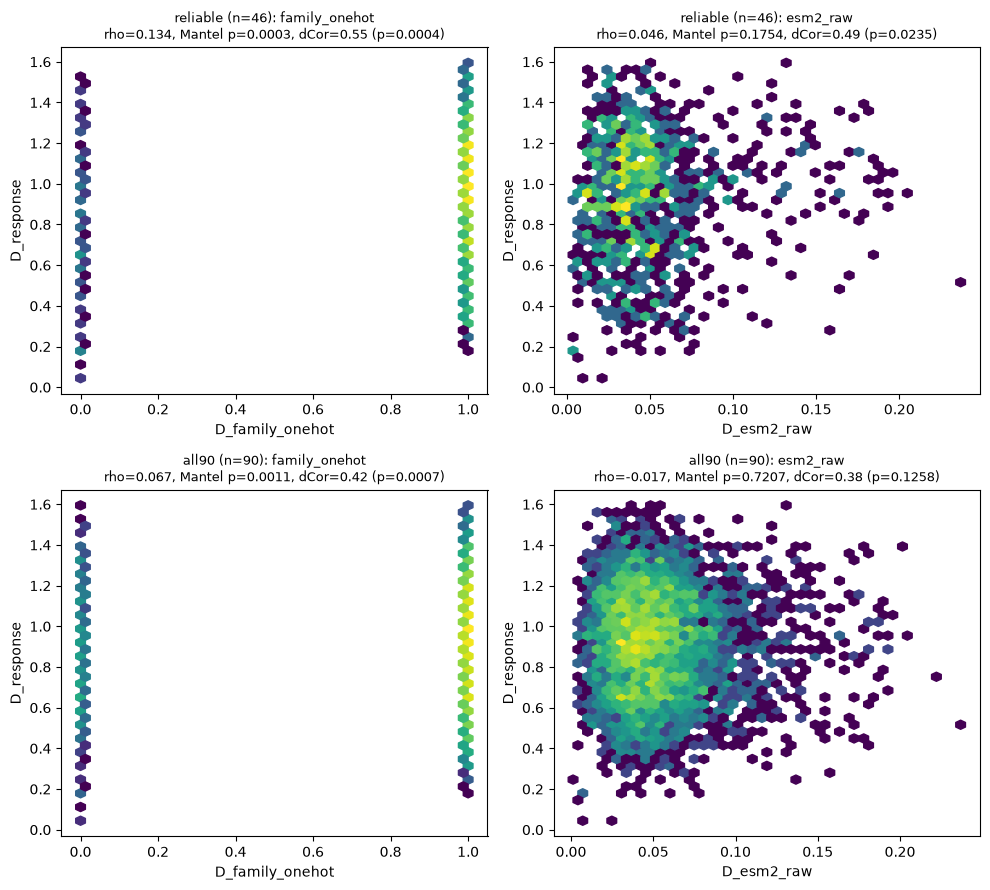

In [6]:
mr=res[(res.subset=="reliable")&(res.cell_type=="all (concatenated)")&~res.representation.isin(["constant","random_gauss"])].set_index("representation")
best=mr.rho.idxmax(); print("best representation on the reliable set:",best,mr.loc[best,["rho","mantel_p"]].astype(float).round(4).to_dict())
fig,axs=plt.subplots(2,2,figsize=(10,9))
for r_,(tag,idx) in enumerate(SUBS.items()):
    I,J=np.triu_indices(len(idx),1); y=D_resp_all[np.ix_(idx,idx)][I,J]
    for c_,name in enumerate([best,"esm2_raw"]):
        x=reps[name][np.ix_(idx,idx)][I,J]; a=axs[r_,c_]; a.hexbin(x,y,gridsize=40,cmap="viridis",mincnt=1,bins="log")
        s=res[(res.representation==name)&(res.subset==tag)&(res.cell_type=="all (concatenated)")].iloc[0]
        a.set_title(f"{tag} (n={len(idx)}): {name}\nrho={s.rho:.3f}, Mantel p={s.mantel_p:.4f}, dCor={s.dcor:.2f} (p={s.dcor_p:.4f})",fontsize=9)
        a.set_xlabel("D_"+name); a.set_ylabel("D_response")
plt.tight_layout(); plt.savefig("../models/22_response_vs_best_vs_esm2.png",dpi=130); plt.show()

# Part B — agonist / antagonist panel (CPU, no training)

**Question.** Does a *structural* representation (ESM2) confuse an agonist with its competitive antagonist, which share a receptor and a fold but have opposite function?

**Pairs.** Antagonist pairs: `IL-1-beta / IL-1Ra` (IL1R1) and `IL-36-alpha / IL-36Ra` (IL1RL2). Positive controls, which should be close in every space: `IL-2 / IL-15` (IL2RB + IL2RG) and `M-CSF / IL-34` (CSF1R).

**Prediction (stated before looking).** Antagonist pairs: NEAR in ESM2, FAR in signed binding (sign flip), FAR in response. Positive controls: near in all three.

**Per pair and per space (every Part A space + the observed response distance `D_response`)** — (1) cosine distance between the members; (2) rank of the partner among the 89 other cytokines by distance, from each member's side (1 = nearest; ties get the average rank); (3) percentile of the pair distance in the full pairwise distribution (4,005 pairs; 0 = closest pair of all, 100 = farthest).

**Caveat checked first.** The response distance of a pair is only interpretable if BOTH members have a reproducible response (split-half r >= 0.5, notebook 20). Pairs failing this are reported and flagged, not dropped.

In [1]:
# self-contained: rebuild the Part A distance matrices if this block is run on its own (identical recipe, no sentence-transformers needed)
import numpy as np, pandas as pd, anndata as ad, glob, scipy.sparse as sp, matplotlib.pyplot as plt
from scipy.stats import rankdata
if "reps" not in globals():
    def cosd(M):
        M=np.asarray(M,float); nn=np.linalg.norm(M,axis=1,keepdims=True); Mn=M/np.where(nn==0,1,nn); D=np.clip(1-Mn@Mn.T,0,2); np.fill_diagonal(D,0); return D
    A=ad.read_h5ad("../data/response_matrix.h5ad"); LIG=list(A.obs_names); n_all=len(LIG)
    R=A.X if not sp.issparse(A.X) else A.X.toarray(); D_resp_all=cosd(R)
    f=glob.glob("/users/scratch1/pavelabramau/data_pavel/cellflow/hf_cache/hub/datasets--theislab--cellflow-datasets/snapshots/*/pbmc_parse.h5ad")[0]
    esm=dict(ad.read_h5ad(f,backed="r").uns["esm2_embeddings"]); E=np.vstack([np.asarray(esm[c],float) for c in LIG])
    F=pd.get_dummies(A.obs["family"].astype(str).values).values.astype(float)
    reps={"esm2_raw":cosd(E),"esm2_centred":cosd(E-E.mean(0)),"binding":np.load("../data/D_binding_signed.npy"),"family_onehot":cosd(F)}
    const=np.ones((n_all,n_all)); np.fill_diagonal(const,0); reps["constant"]=const
    reps["random_gauss"]=cosd(np.random.default_rng(0).normal(size=(n_all,64)))
    reps["uniprot_text"]=cosd(np.load("../data/uniprot_text_embedding.npy"))
REL=pd.read_csv("../data/reliability.csv").set_index("cytokine")
SPACES=dict(reps); SPACES["RESPONSE (observed)"]=D_resp_all
PAIRS=[("IL-1-beta","IL-1Ra","antagonist","IL1R1"),("IL-36-alpha","IL-36Ra","antagonist","IL1RL2"),("IL-2","IL-15","positive control","IL2RB+IL2RG"),("M-CSF","IL-34","positive control","CSF1R")]
assert all(a in LIG and b in LIG for a,b,_,_ in PAIRS)
I,J=np.triu_indices(len(LIG),1)

In [2]:
rows=[]
for a,b,kind,rec in PAIRS:
    ia,ib=LIG.index(a),LIG.index(b)
    for sp_,D in SPACES.items():
        d=D[ia,ib]; allp=D[I,J]
        ra=rankdata(np.delete(D[ia],[ia]),method="average")[ (ib if ib<ia else ib-1) ]   # rank of b among the 89 others of a
        rb=rankdata(np.delete(D[ib],[ib]),method="average")[ (ia if ia<ib else ia-1) ]
        rows.append(dict(pair=f"{a} / {b}",kind=kind,receptor=rec,space=sp_,distance=d,rank_b_from_a=ra,rank_a_from_b=rb,
                         percentile=100*(np.sum(allp<d)+0.5*np.sum(allp==d))/len(allp),n_tied_at_d=int(np.sum(allp==d))))
T=pd.DataFrame(rows)
rel=pd.DataFrame([dict(pair=f"{a} / {b}",member_a=a,r_a=REL.loc[a,"r_split_half"],member_b=b,r_b=REL.loc[b,"r_split_half"],
        both_reliable=bool(REL.loc[a,"reliable"] and REL.loc[b,"reliable"]),category_a=REL.loc[a,"category"],category_b=REL.loc[b,"category"]) for a,b,_,_ in PAIRS])
print("RELIABILITY CHECK (split-half r >= 0.5 needed for BOTH members):"); print(rel.to_string(index=False))
bad=[p for p,ok in zip(rel.pair,rel.both_reliable) if not ok]
print("\n-> response distance NOT interpretable for:",bad if bad else "none")
T["response_interpretable"]=T.pair.map(dict(zip(rel.pair,rel.both_reliable)))
T.to_csv("../data/agonist_antagonist_panel.csv",index=False)
# one small table: rows = pairs, columns = spaces; cell = distance | rank(a->b, b->a) | percentile
W=T.assign(cell=lambda x:x.apply(lambda r:f"{r.distance:.3f} | r{r.rank_b_from_a:.0f},{r.rank_a_from_b:.0f} | p{r.percentile:.0f}",axis=1)).pivot(index="pair",columns="space",values="cell")
W=W.loc[[f"{a} / {b}" for a,b,_,_ in PAIRS],list(SPACES)]; W.insert(0,"response ok?",[ "yes" if ok else "NO" for ok in rel.both_reliable]); W.insert(0,"kind",[k for _,_,k,_ in PAIRS])
print("\ncell = cosine distance | rank of partner among 89 others (a->b, b->a) | percentile in all 4,005 pairs (0 = closest)"); print(W.to_string())

RELIABILITY CHECK (split-half r >= 0.5 needed for BOTH members):
                 pair    member_a      r_a member_b      r_b  both_reliable                                               category_a                                               category_b
   IL-1-beta / IL-1Ra   IL-1-beta 0.877502   IL-1Ra 0.572757           True                                        reliable (r>=0.5)                                        reliable (r>=0.5)
IL-36-alpha / IL-36Ra IL-36-alpha 0.418719  IL-36Ra 0.151712          False low r, response <= 2x well null (no detectable response) low r, response <= 2x well null (no detectable response)
         IL-2 / IL-15        IL-2 0.915769    IL-15 0.922971           True                                        reliable (r>=0.5)                                        reliable (r>=0.5)
        M-CSF / IL-34       M-CSF 0.785138    IL-34 0.654766           True                                        reliable (r>=0.5)                                        rel

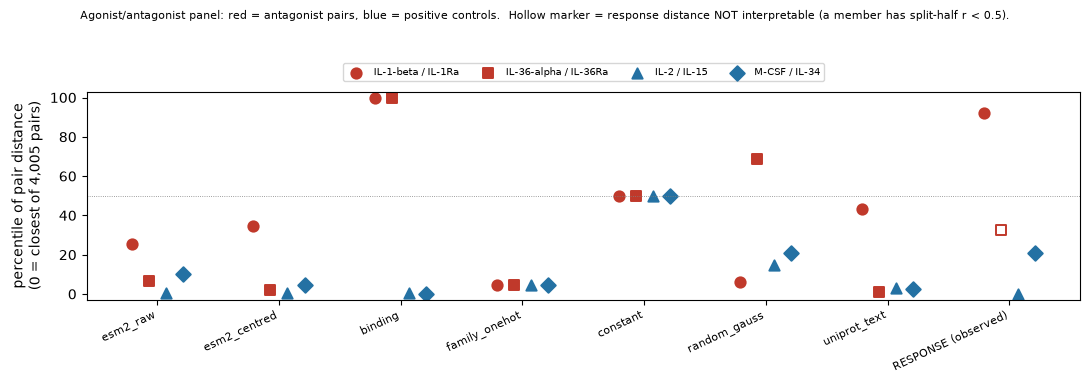

In [3]:
spaces=list(SPACES); fig,ax=plt.subplots(figsize=(11,3.8))
cols={"antagonist":"#c0392b","positive control":"#2471a3"}; mk=["o","s","^","D"]
for k,(a,b,kind,rec) in enumerate(PAIRS):
    t=T[T.pair==f"{a} / {b}"].set_index("space").loc[spaces]; ok=bool(rel.both_reliable[k])
    xs=np.arange(len(spaces))+(k-1.5)*0.14
    for x,s in zip(xs,spaces):
        hollow=(s=="RESPONSE (observed)" and not ok)
        ax.scatter(x,t.loc[s,"percentile"],marker=mk[k],s=55,facecolors="none" if hollow else cols[kind],edgecolors=cols[kind],linewidths=1.4,label=f"{a} / {b}" if s==spaces[0] else None)
ax.set_xticks(range(len(spaces))); ax.set_xticklabels(spaces,rotation=25,ha="right",fontsize=8); ax.set_ylabel("percentile of pair distance\n(0 = closest of 4,005 pairs)")
ax.axhline(50,color="grey",lw=.6,ls=":"); ax.set_ylim(-3,103); ax.legend(fontsize=7,ncol=4,loc="upper center",bbox_to_anchor=(.5,1.16))
fig.suptitle("Agonist/antagonist panel: red = antagonist pairs, blue = positive controls.  Hollow marker = response distance NOT interpretable (a member has split-half r < 0.5).",fontsize=8,y=0.995)
plt.tight_layout(); plt.savefig("../models/22_agonist_antagonist.png",dpi=130); plt.show()